In [114]:
import pandas as pd
import numpy as np
from pyparsing import col

df_analysis = pd.read_csv("soccer_players_clean.csv")

C:\Users\Titus\AppData\Local\Temp\ipykernel_34264\807362253.py:5: DtypeWarning: Columns (0: weak_foot) have mixed types. Specify dtype option on import or set low_memory=False.
  df_analysis = pd.read_csv("soccer_players_clean.csv")


In [115]:
# Create Primary position
def position_group(pos):
    if pd.isna(pos):
        return "Unknown"

    primary = str(pos).split(",")[0].strip()

    mapping = {
        "GK": "Goalkeeper",
        "DF": "Defender",
        "MF": "Midfielder",
        "FW": "Forward"
    }

    return mapping.get(primary, "Other")


df_analysis["position_group"] = (
    df_analysis["pos"]
    .apply(position_group)
)

print(
    df_analysis["position_group"]
    .value_counts()
)


position_group
Defender      10561
Midfielder     8937
Forward        6633
Goalkeeper     2303
Unknown           2
Name: count, dtype: int64


C:\Users\Titus\AppData\Local\Temp\ipykernel_34264\98781321.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_analysis["position_group"] = (


In [116]:
print(df_analysis["minutes"].describe())

print(
    df_analysis["minutes"]
    .quantile([0,.10,.25,.50,.75,.90,.95,1])
)

MIN_MINUTES = 450

df_analysis= df_analysis[
    df_analysis["minutes"] >= MIN_MINUTES
].copy()

print(df_analysis.shape)



count    28436.000000
mean      1587.374596
std        879.955803
min        180.000000
25%        834.000000
50%       1551.000000
75%       2293.000000
max       7444.000000
Name: minutes, dtype: float64
0.00     180.0
0.10     416.0
0.25     834.0
0.50    1551.0
0.75    2293.0
0.90    2776.0
0.95    2972.0
1.00    7444.0
Name: minutes, dtype: float64
(25267, 136)


# EDA

In [117]:
#Players by position
print(df_analysis["pos"].value_counts())




pos
DF       8058
MF       5306
FW       2931
FW,MF    2721
MF,FW    2024
GK       1916
DF,MF    1216
MF,DF     621
DF,FW     342
FW,DF     132
Name: count, dtype: int64


In [118]:
#Players by season
print(
    df_analysis["season"]
    .value_counts()
    .sort_index()
)

season
1718    3052
1819    3009
1920    3071
2021    3279
2122    2983
2223    3503
2324    3794
2425    2576
Name: count, dtype: int64


In [119]:
#Players by league
print(
    df_analysis["league"]
    .value_counts()
    .head(20)
)

league
USA-MLS                   3219
ITA-Serie A               2704
ESP-La Liga               2643
ENG-Premier League        2542
TUR-Super Lig             2523
NED-Eredivisie            2491
GER-Bundesliga            2348
POR-Primeira Liga         2316
FRA-Ligue 1               2277
BEL-Jupiler Pro League    2204
Name: count, dtype: int64


In [120]:
#Summary of important statistics
eda_features = [
    "goals_per90",
    "assists_per90",
    "xg_per90",
    "xag_per90",
    "pass_completion_pct"
]

print(df_analysis[eda_features].describe())


        goals_per90  assists_per90      xg_per90     xag_per90  \
count  25267.000000   25267.000000  21817.000000  21817.000000   
mean       0.129277       0.089979      0.134740      0.093426   
std        0.175162       0.107253      0.156131      0.086772   
min        0.000000       0.000000      0.000000      0.000000   
25%        0.000000       0.000000      0.030000      0.020000   
50%        0.060000       0.060000      0.070000      0.070000   
75%        0.190000       0.140000      0.190000      0.140000   
max        1.580000       0.940000      1.770000      0.850000   

       pass_completion_pct  
count         21815.000000  
mean             76.846748  
std               8.382920  
min               0.000000  
25%              71.400000  
50%              77.500000  
75%              83.100000  
max             100.000000  


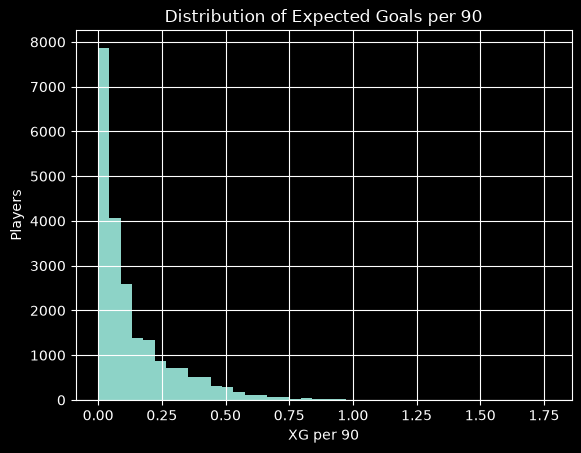

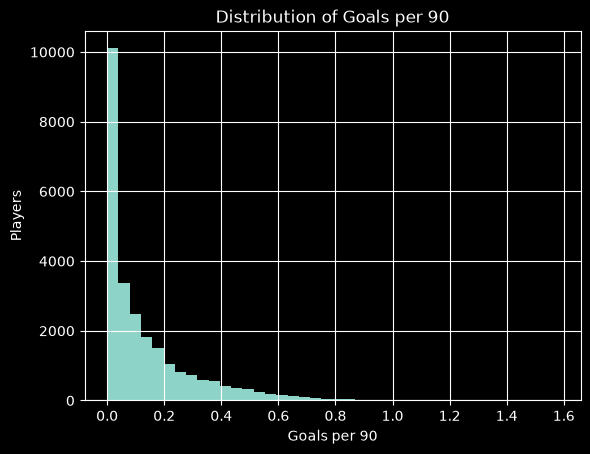

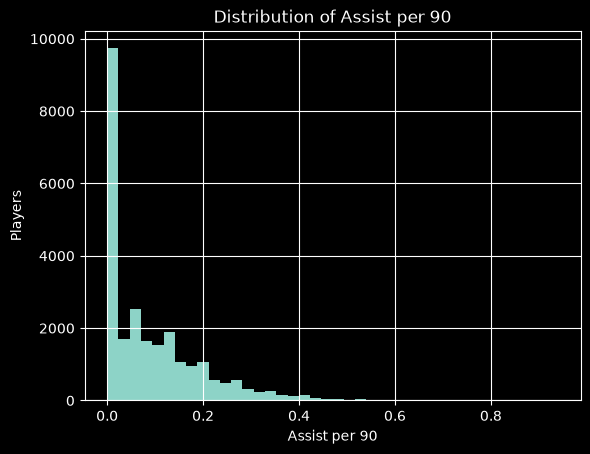

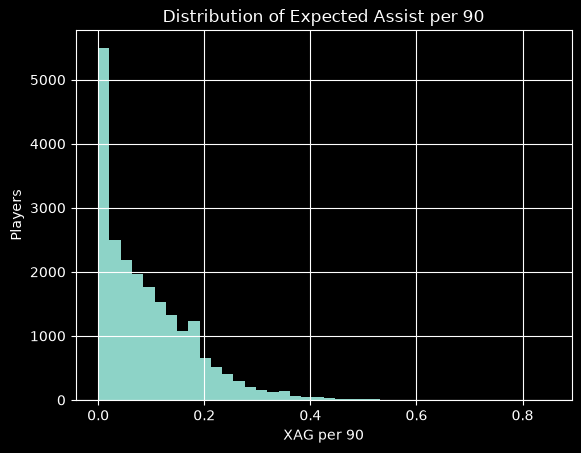

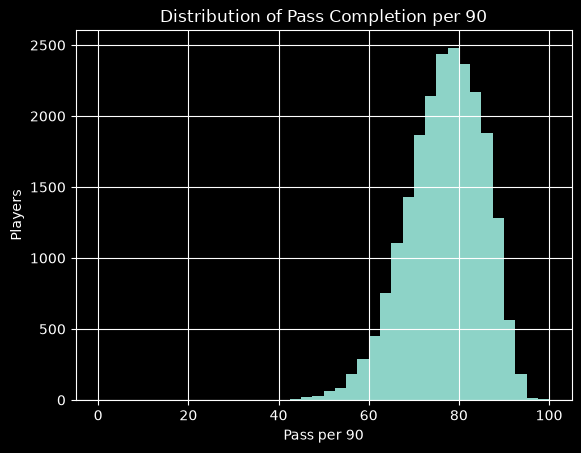

In [121]:
import matplotlib.pyplot as plt

df_analysis["xg_per90"].hist(bins=40)

plt.xlabel("XG per 90")
plt.ylabel("Players")
plt.title("Distribution of Expected Goals per 90")
plt.show()

df_analysis["goals_per90"].hist(bins=40)

plt.xlabel("Goals per 90")
plt.ylabel("Players")
plt.title("Distribution of Goals per 90")
plt.show()

df_analysis["assists_per90"].hist(bins=40)

plt.xlabel("Assist per 90")
plt.ylabel("Players")
plt.title("Distribution of Assist per 90")
plt.show()

df_analysis["xag_per90"].hist(bins=40)

plt.xlabel("XAG per 90")
plt.ylabel("Players")
plt.title("Distribution of Expected Assist per 90")
plt.show()

df_analysis["pass_completion_pct"].hist(bins=40)

plt.xlabel("Pass per 90")
plt.ylabel("Players")
plt.title("Distribution of Pass Completion per 90")
plt.show()



In [122]:
def fifa_position_groups(position):

    if pd.isna(position):
        return {"Unknown"}

    positions = [
        p.strip()
        for p in str(position).split(",")
    ]

    groups = set()

    for pos in positions:

        if pos == "GK":
            groups.add("Goalkeeper")

        elif pos in ["CB", "LB", "RB", "LWB", "RWB"]:
            groups.add("Defender")

        elif pos in ["CDM", "CM", "CAM", "LM", "RM"]:
            groups.add("Midfielder")

        elif pos in ["ST", "CF", "LW", "RW"]:
            groups.add("Forward")

    return groups if groups else {"Other"}

In [123]:
def fbref_position_groups(position):

    if pd.isna(position):
        return {"Unknown"}

    positions = [
        p.strip()
        for p in str(position).split(",")
    ]

    mapping = {
        "GK": "Goalkeeper",
        "DF": "Defender",
        "MF": "Midfielder",
        "FW": "Forward"
    }

    groups = {
        mapping[p]
        for p in positions
        if p in mapping
    }

    return groups if groups else {"Other"}

In [124]:
df_analysis["fifa_position_groups"] = (
    df_analysis["player_positions"]
    .apply(fifa_position_groups)
)

df_analysis["fbref_position_groups"] = (
    df_analysis["pos"]
    .apply(fbref_position_groups)
)

In [125]:
def positions_conflict(row):

    fifa = row["fifa_position_groups"]
    fbref = row["fbref_position_groups"]

    return fifa.isdisjoint(fbref)

In [126]:
df_analysis["position_conflict"] = (
    df_analysis.apply(
        positions_conflict,
        axis=1
    )
)

position_conflicts = df_analysis[
    df_analysis["position_conflict"]
][
    [
        "player",
        "team",
        "pos",
        "player_positions",
        "fbref_position_groups",
        "fifa_position_groups"
    ]
]

print(position_conflicts.head(50))

print(
    "True position conflicts:",
    len(position_conflicts)
)


                     player              team    pos player_positions  \
17                  Ederson          Atalanta     MF               GK   
79           Kingsley Coman     Bayern Munich     FW           LM, RM   
125              Leroy Sane     Bayern Munich     FW           RM, LM   
172            Filip Kostic          Juventus     DF           LM, LW   
223             Dusan Tadic        Fenerbahçe     MF       LW, CF, RW   
377            Kaoru Mitoma          Brighton     FW               LM   
383           Claudio Bravo  Portland Timbers     DF               GK   
426          Alex Berenguer     Athletic Club     FW           LM, RM   
445           Nico Williams     Athletic Club     FW           RM, LM   
457          Carlos Augusto             Inter     DF               LM   
545             Solly March          Brighton  FW,DF               RM   
555             Ayoze Perez             Betis     FW      LM, RM, CAM   
622                  Marcao  Fatih Karagümrük     F

In [127]:
def conflict_severity(row):

    fbref = row["fbref_position_groups"]
    fifa = row["fifa_position_groups"]

    # No conflict
    if not fbref.isdisjoint(fifa):
        return "None"

    # Goalkeeper vs outfield = severe
    if (
        ("Goalkeeper" in fbref and "Goalkeeper" not in fifa)
        or
        ("Goalkeeper" in fifa and "Goalkeeper" not in fbref)
    ):
        return "High"

    # Defender vs forward is fairly suspicious
    if (
        ("Defender" in fbref and "Forward" in fifa)
        or
        ("Forward" in fbref and "Defender" in fifa)
    ):
        return "Medium"

    # MF/FW differences are common
    return "Low"

In [128]:
df_analysis["conflict_severity"] = (
    df_analysis.apply(
        conflict_severity,
        axis=1
    )
)

print(
    df_analysis["conflict_severity"]
    .value_counts()
)

conflict_severity
None      24687
Low         435
Medium       88
High         57
Name: count, dtype: int64


In [129]:
df_model = df_analysis[
    df_analysis["conflict_severity"] != "High"
].copy()

midfielders = df_model[
    df_model["position_group"] == "Midfielder"
].copy()


In [130]:
midfielder_features = [
    #Scoring
    "goals_per90",
    "xg_per90",

    #Chance Creation
    "assists_per90",
    "xag_per90",
    "per_90_minutes_kp",
    "sca_sca90",

    #Progression
    "per_90_minutes_prgp",
    "per_90_minutes_prgc",
    "per_90_minutes_1_per_3",
    "per_90_minutes_ppa",


    #Possession/passing
    "pass_completion_pct",

    #Defense
    "per_90_minutes_tackles_tkl",
    "per_90_minutes_int"

]

#add other positions here later

missing_features = [
    col
    for col in midfielder_features
    if col not in df_analysis.columns
]
print("Missing features:", missing_features)


Missing features: []


In [131]:
midfielders = df_model[
    df_model["position_group"] == "Midfielder"
].copy()

print("Midfielder observations:", len(midfielders))
X = midfielders[midfielder_features].copy()

print(X.shape)
print(X.head())

midfielders.to_csv("midfielders_analysis_ready.csv",index=False)


Midfielder observations: 7930
(7930, 13)
    goals_per90  xg_per90  assists_per90  xag_per90  per_90_minutes_kp  \
2          0.29      0.18           0.74       0.85           4.338235   
9          0.25      0.12           0.28       0.12           1.503067   
12         0.05      0.16           0.09       0.05           0.727273   
15         0.06      0.11           0.22       0.18           1.517028   
18         0.04      0.05           0.25       0.30           2.975207   

    sca_sca90  per_90_minutes_prgp  per_90_minutes_prgc  \
2        7.36             8.161765             3.455882   
9        4.82            11.533742             2.331288   
12       1.86             5.090909             0.545455   
15       3.69             7.151703             3.219814   
18       5.29             9.462810             2.314050   

    per_90_minutes_1_per_3  per_90_minutes_ppa  pass_completion_pct  \
2                 4.926471            4.117647                 75.4   
9                